In [ ]:
def metrics(y_true, y_pred):
    """Common regression skill scores for continuous targets (usually MAR).

    mae  — mean absolute error (same units as the target; lower is better)
    corr — Pearson correlation between observations and predictions
    r2   — coefficient of determination (1 = perfect; can be negative)
    """
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "corr": float(np.corrcoef(y_true.ravel(), y_pred.ravel())[0, 1]),
        "r2": float(r2_score(y_true, y_pred)),
    }


def plot_pred_scatter(y_train, train_pred, y_test, test_pred, title):
    """Observed vs predicted scatter for train and test sites.

    The dashed line is the 1:1 relation: predictions near it are accurate.
    """
    tr = metrics(y_train, train_pred)
    te = metrics(y_test, test_pred)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(y_train, train_pred, s=8, alpha=0.35, label=f"train MAE={tr['mae']:.2f}, r={tr['corr']:.3f}")
    ax.scatter(y_test, test_pred, s=8, alpha=0.45, label=f"test MAE={te['mae']:.2f}, r={te['corr']:.3f}")
    lims = [
        min(y_train.min(), y_test.min(), train_pred.min(), test_pred.min()),
        max(y_train.max(), y_test.max(), train_pred.max(), test_pred.max()),
    ]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlabel("Observed")
    ax.set_ylabel("Predicted")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.set_aspect("equal", adjustable="box")
    plt.tight_layout()
    plt.show()
    return tr, te


## Load paired MAR and TOC observations

We train one network on two related sediment properties at the same locations:

- **MAR** — mass accumulation rate (primary target)
- **TOC** — total organic carbon (auxiliary task that shares representation with MAR)

Features are the 113-d neural-network–imputed environmental predictors (values only).
The train/test split is stratified by MAR deciles.


In [1]:
# Load CS + DO cores for both tasks with a shared geographic train/test split.
mar = load_mar_cs_do(preprocess_features_labels)
toc = load_toc_cs_do(preprocess_features_labels)

# MAR (sedimentation / mass-accumulation) matrices
sedrate_train_features = mar["train_features"]
sedrate_train_labels = mar["train_labels"]
sedrate_test_features = mar["test_features"]
sedrate_test_labels = mar["test_labels"]
sedrate_features = mar["features"]  # all sites — used to size the network

# TOC matrices — same sites, different response variable
toc_train_features = toc["train_features"]
toc_train_labels = toc["train_labels"]
toc_test_features = toc["test_features"]
toc_test_labels = toc["test_labels"]

# Standardization stats for later global-grid prediction
X_mean, X_std = mar["x_mean"], mar["x_std"]
world_dir = mar["world_dir"]

print("MAR train/test:", sedrate_train_features.shape, sedrate_test_features.shape)
print("TOC train/test:", toc_train_features.shape, toc_test_features.shape)
print("n_features:", mar["n_features"])


n_features=113 (NN-imputed values only)
train=(9860, 113), test=(3288, 113)
CS path: data/interim/inputfeatures/CS_men_masked
DO path: data/interim/inputfeatures/DO_men_masked
world: data/interim/worldfeatures/World_Features_men_masked


## Mini-batch iterators and loss function

Training proceeds in **mini-batches**: small random subsets of sites are shown
to the model in each step. Separate loaders for MAR and TOC let the multi-task
trainer alternate updates on both heads.

The objective is **Huber loss**, which behaves like squared error for small
residuals and like absolute error for large residuals — useful for heavy-tailed MAR.


In [ ]:
# Number of sites shown to the network in one optimization step
batch_size = 32

# Training loaders: shuffle=True randomizes site order each epoch
train_dataloaders = {
    "sedimentation_rates": DataLoader(
        TensorDataset(
            torch.tensor(sedrate_train_features, dtype=torch.float32),
            torch.tensor(sedrate_train_labels, dtype=torch.float32),
        ),
        batch_size=batch_size,
        shuffle=True,
    ),
    "toc": DataLoader(
        TensorDataset(
            torch.tensor(toc_train_features, dtype=torch.float32),
            torch.tensor(toc_train_labels, dtype=torch.float32),
        ),
        batch_size=batch_size,
        shuffle=True,
    ),
}

# Test loaders: shuffle=False keeps evaluation deterministic
test_dataloaders = {
    "sedimentation_rates": DataLoader(
        TensorDataset(
            torch.tensor(sedrate_test_features, dtype=torch.float32),
            torch.tensor(sedrate_test_labels, dtype=torch.float32),
        ),
        batch_size=batch_size,
        shuffle=False,
    ),
    "toc": DataLoader(
        TensorDataset(
            torch.tensor(toc_test_features, dtype=torch.float32),
            torch.tensor(toc_test_labels, dtype=torch.float32),
        ),
        batch_size=batch_size,
        shuffle=False,
    ),
}

# Robust regression loss (less sensitive to extreme MAR outliers than MSE alone)
loss_fn = torch.nn.HuberLoss()


## Fit the multi-task feed-forward network

This cell builds and trains a **multi-task learning (MTL)** model:

1. Shared hidden layers learn a joint representation of the environmental predictors.
2. Task-specific heads then predict **MAR** and **TOC** from that representation.

Architecture below was selected by a held-out hyperparameter search: four hidden
layers of width 128 with **two shared layers** (map configuration 47 in the search
log). Training uses early stopping on validation MAR loss; the learning curves
show whether the fit is stable or overfits.


Training MTL model 46 with layer_widths=[128, 128, 128, 128] and num_shared_layers=2
torch.Size([9860, 113])
Train Labels Distribution(Sedimentation Rates):
Count: 9860
Mean: 124.115
Std: 210.546
Min: 0.000
Max: 5070.000

Test Labels Distribution(Sedimentation Rates):
Count: 3288
Mean: 123.683
Std: 199.082
Min: 0.000
Max: 1794.000
Number of zeros in train labels: 27
Number of zeros in test labels: 8
Train Labels Distribution(TOC):
Count: 15843
Mean: 0.722
Std: 1.103
Min: 0.000
Max: 22.300

Test Labels Distribution(TOC):
Count: 5281
Mean: 0.731
Std: 1.172
Min: 0.000
Max: 21.200
Number of zeros in train labels: 9
Number of zeros in test labels: 2
torch.Size([9860, 113])
torch.Size([9860])
47
MTLNN(
  (encoder): Sequential(
    (0): Linear(in_features=113, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
  )
  (task_sedimentation_rates_hea

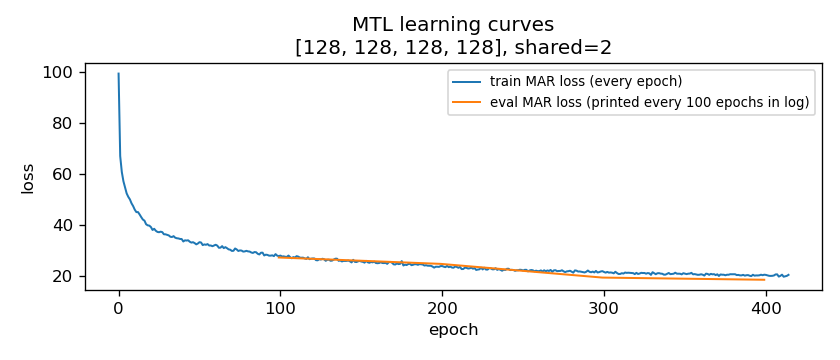

In [2]:
# Architecture from hyperparameter search (held-out MAR skill):
#   layer_widths      — hidden-layer sizes of the shared trunk + heads
#   num_shared_layers — how many leading layers are shared by MAR and TOC
layer_widths = [128, 128, 128, 128]
num_shared_layers = 2
num_epochs = 2000  # upper bound; early stopping usually ends sooner

train_step = 2     # alternate MAR / TOC updates inside the multi-task trainer
write_maps = True  # if True, later cell writes global ocean prediction grids
count_mtl = 47     # search-log id for this architecture (used in output filenames)

# Fix random seeds so weight initialization is reproducible
set_seed(42)
model = buildDNN(layer_widths, sedrate_features, num_shared_layers)
model.double()  # float64 — matches the numerical precision used in the search

# Optimize network weights. Returns per-epoch multi-task losses and the LR schedule.
training_losses, learning_rate, evaluation_losses = train_model(
    model,
    loss_fn,
    train_dataloaders,
    test_dataloaders,
    train_step=train_step,
    num_epochs=num_epochs,
)

out_dir = PREDICTION_MAPS_DIR / "notebooks_mtl"
out_dir.mkdir(parents=True, exist_ok=True)

# Helper: pull the MAR entry out of a multi-task loss dict for plotting
def _sed_loss(x):
    return x["sedimentation_rates"] if isinstance(x, dict) else float(x)

# Learning curves: falling train+eval → improving fit; rising eval alone → overfitting
train_curve = [_sed_loss(v) for v in training_losses]
eval_curve = [_sed_loss(v) for v in evaluation_losses]
plt.figure(figsize=(7, 3))
plt.plot(train_curve, label="train MAR loss")
plt.plot(eval_curve, label="eval MAR loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title(f"MTL learning curves\n{layer_widths}, shared={num_shared_layers}")
plt.tight_layout()
plt.show()  # figure is shown below this cell


## Evaluate predictive skill and map global fields

With the fitted network we:

1. Score **train** and **test** sites for both MAR and TOC (MAE, correlation, $R^2$).
2. Draw observed-vs-predicted scatter plots.
3. Save network weights for reuse.
4. Optionally apply the model to the global ocean feature grid to produce continuous
   MAR and TOC prediction maps (land cells zeroed with an island mask).

> **Note on displayed outputs.** Cell outputs (training logs, learning curves, scatter plots, and maps) are taken from the archived hyperparameter-search run of **this same architecture**, not from a fresh execution of the cells above. Metrics therefore match the selected configuration; cosmetic plot styling may differ slightly from what `plot_pred_scatter` would draw if re-run locally.


=== Test Set Results ===

Task: sedimentation_rates
MAE: 18.9012
MSE: 5929.1406
Correlation Coefficient: 0.9228
R² Score: 0.8504

Task: toc
MAE: 0.3080
MSE: 0.5946
Correlation Coefficient: 0.7673
R² Score: 0.5674
[SI scatter] Saved scatter_entire_mtl.png: train MAE=14.21 CC=0.908; test MAE=18.90 CC=0.923
[SI scatter] Saved checkpoint /gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/models/MTL_single_nomask_map47_[128,128,128,128]_shared2_from_hp_sweep.pt
cuda:0
... [59 prediction-chunk lines omitted] ...
prediction 60 done!
... [59 prediction-chunk lines omitted] ...
prediction 120 done!
... [59 prediction-chunk lines omitted] ...
prediction 180 done!
... [59 prediction-chunk lines omitted] ...
prediction 240 done!
... [59 prediction-chunk lines omitted] ...
prediction 300 done!
... [58 prediction-chunk lines omitted] ...
prediction 359 done!
prediction 360 done!


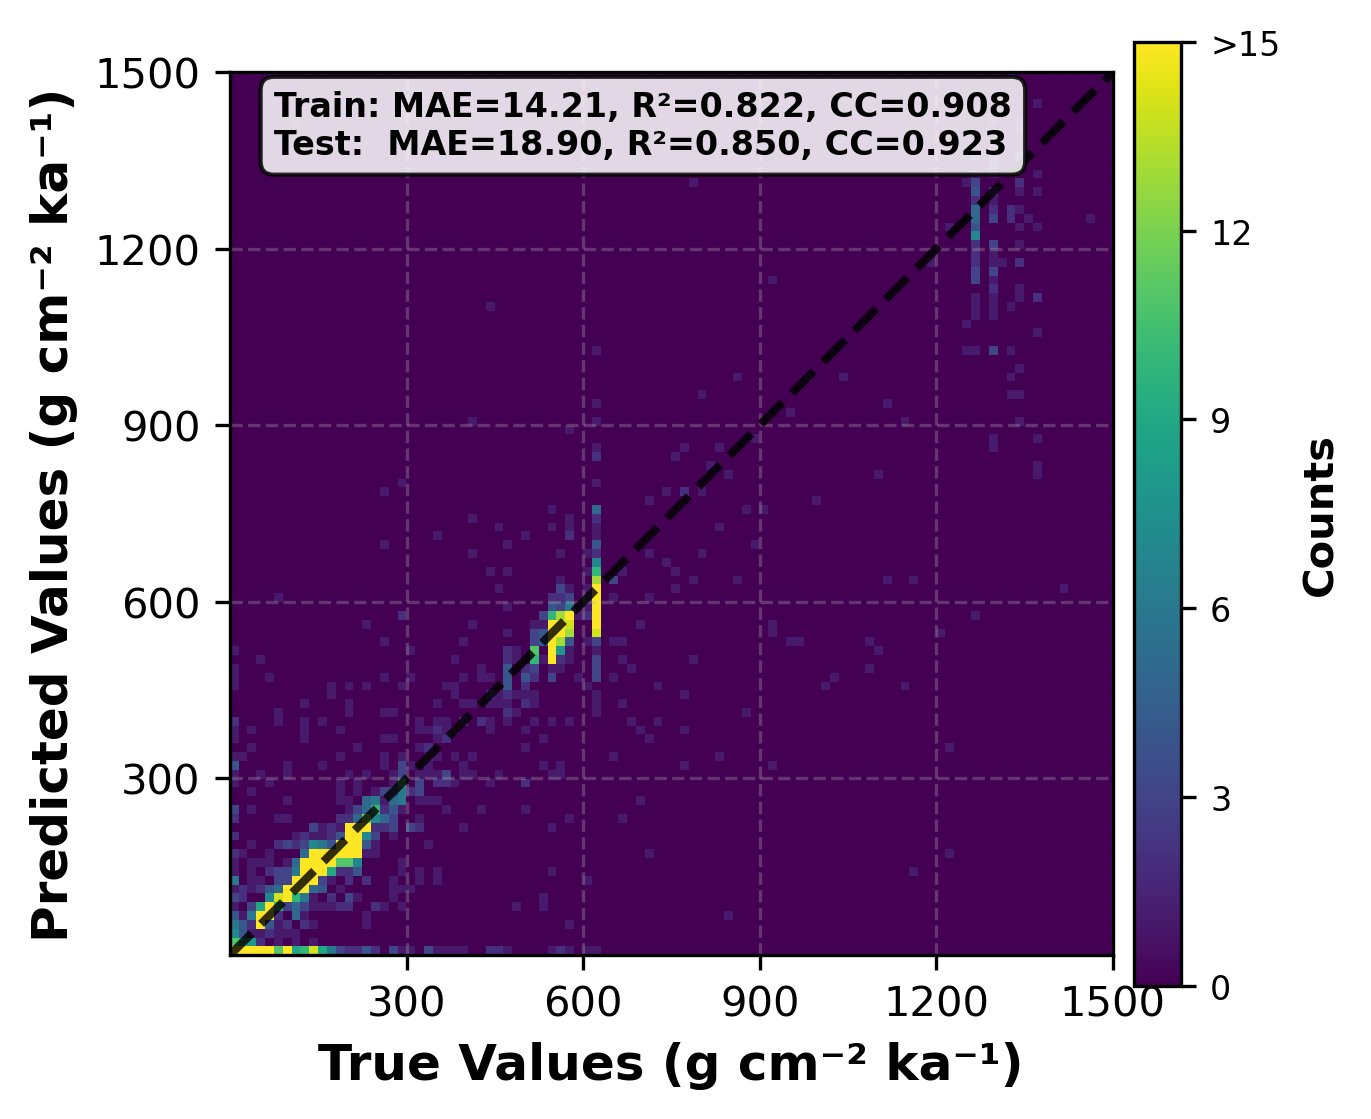

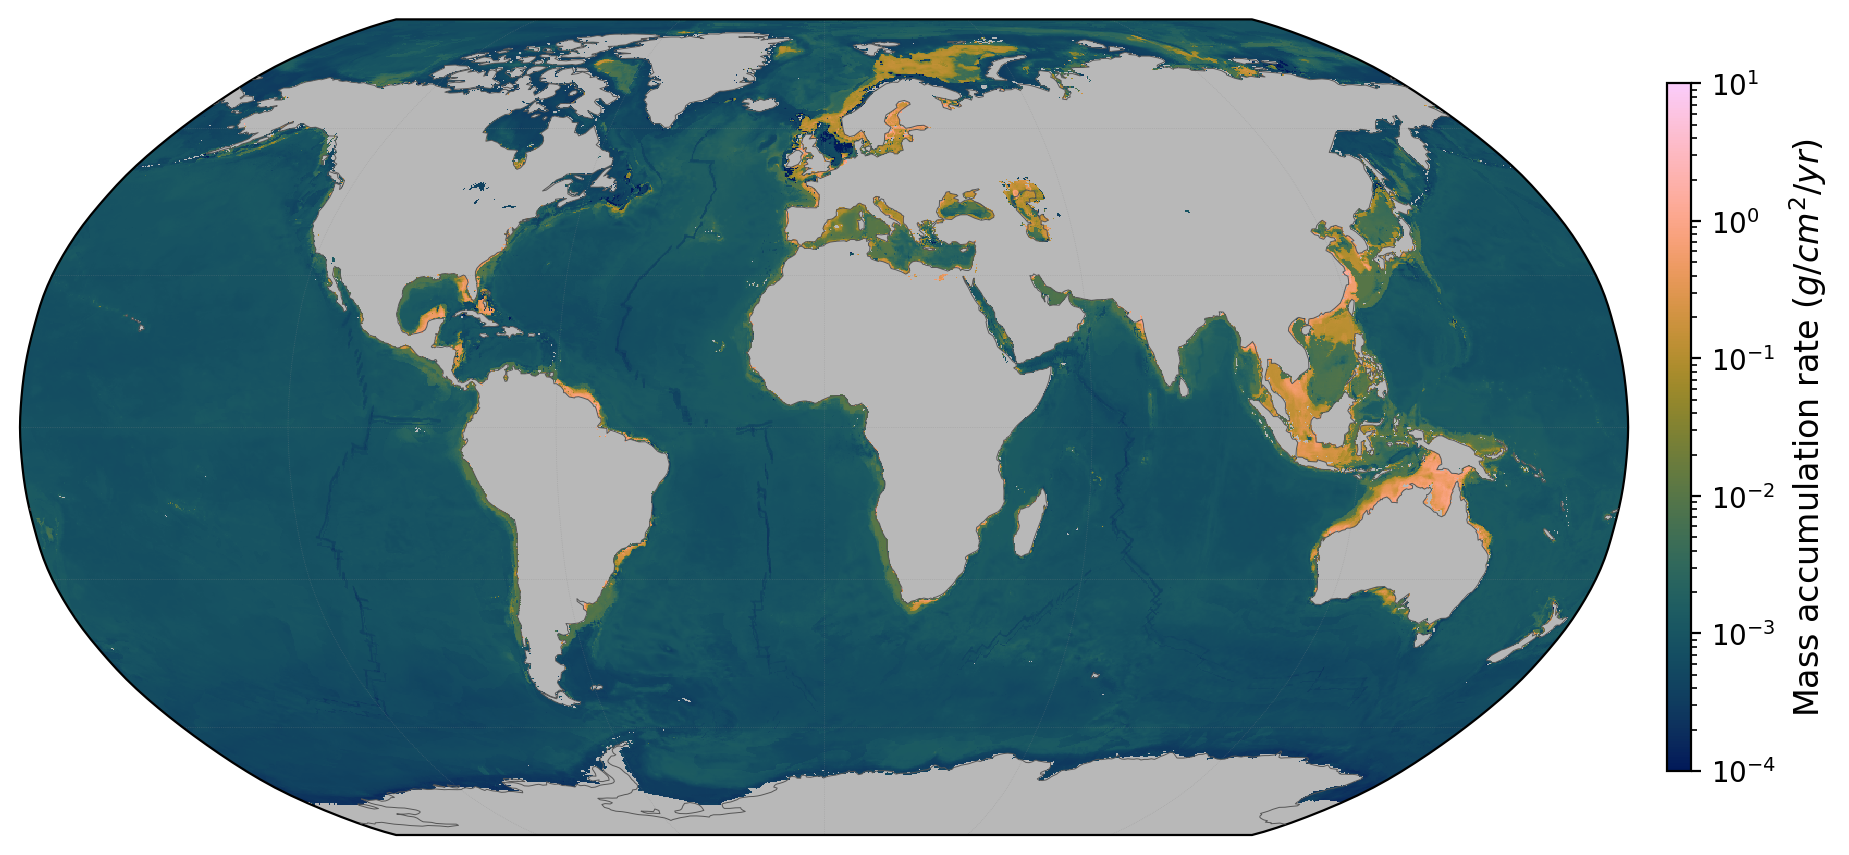

In [3]:
# --- helpers -----------------------------------------------------------------

def collect_task_predictions(model, loader, task):
    """Run the network on every batch and collect labels + predictions.

    `task` selects which head to read: "sedimentation_rates" (MAR) or "toc".
    """
    model.eval()  # turn off dropout / training-only behaviour
    ys, ps = [], []
    with torch.no_grad():  # evaluation does not update weights
        for x, y in loader:
            x = x.to(device=device, dtype=torch.float64)
            _decoded, out = model(x, task_id=task)
            ys.append(y.numpy().reshape(-1))
            ps.append(out.detach().cpu().numpy().reshape(-1))
    return np.concatenate(ys), np.concatenate(ps)


# --- skill scores + scatter plots for both tasks -----------------------------

rows = []
for task, label in [("sedimentation_rates", "MAR"), ("toc", "TOC")]:
    y_tr, p_tr = collect_task_predictions(model, train_dataloaders[task], task)
    y_te, p_te = collect_task_predictions(model, test_dataloaders[task], task)
    tr, te = plot_pred_scatter(y_tr, p_tr, y_te, p_te, f"MTL — {label}")
    rows.append({"task": label, **{f"test_{k}": v for k, v in te.items()}})

pd.DataFrame(rows).to_csv(out_dir / "mtl_test_summary.csv", index=False)

arch = str(layer_widths).replace(" ", "")
weight_path = out_dir / f"model_MTL_map{count_mtl}_{arch}_shared{num_shared_layers}_nnimputed.pt"
torch.save(model.state_dict(), weight_path)
print("Saved weights:", weight_path)


# --- optional: global ocean prediction maps ----------------------------------

if write_maps:
    chunk_shape = (6, 4320)  # spatial layout of one stored world-feature file
    files = sorted(p for p in world_dir.iterdir() if p.suffix == ".npy")
    map_mar = map_toc = None
    model.eval()
    with torch.no_grad():
        for i, f in enumerate(files):
            feats = normalize_world_chunk(np.load(f), X_mean, X_std)
            t = torch.tensor(feats, dtype=torch.float64, device=device)
            _, p_mar = model(t, task_id="sedimentation_rates")
            _, p_toc = model(t, task_id="toc")
            p_mar = p_mar.detach().cpu().numpy().reshape(chunk_shape)
            p_toc = p_toc.detach().cpu().numpy().reshape(chunk_shape)
            map_mar = p_mar if map_mar is None else np.append(map_mar, p_mar, axis=0)
            map_toc = p_toc if map_toc is None else np.append(map_toc, p_toc, axis=0)
            if (i + 1) % 60 == 0:
                print(f"  predicted {i+1}/{len(files)} chunks")
            del t, feats
            gc.collect()

    land = np.load(DATA_RAW / "island_map.npy")
    land = np.where(np.isnan(land), 1, land).astype(bool)
    for arr, name in [(map_mar, "MAR"), (map_toc, "toc")]:
        arr = np.rot90(np.rot90(np.fliplr(arr)))
        arr[land] = 0
        path = out_dir / f"prediction_map_{name}_entire_MTL_map{count_mtl}_nnimputed.npy"
        np.save(path, arr)
        print("Saved:", path)
